# AdaBoost for Regression — Problem 2: Worked Solution

This notebook solves the practice problem **by computation**: every number below
(errors, voting powers, weights, plots) is produced by the code, not typed in by hand.
We follow **AdaBoost.R2** (Drucker, 1997) for three rounds, then combine the stumps
with a **weighted median**.

## The problem

Regression data with one input variable $x$:

| Row | $x$ | $y$ |
|-----|-----|-----|
| 0–4 | 1–5 | 2 |
| 5 | 6 | 7 |
| 6 | 7 | 7 |
| 7 | 8 | 4 |
| 8 | 9 | 4 |
| 9 | 10 | 10 |

The three stumps are **given**:

- **Stump 1:** if $x \le 5.5$ predict $2.0$, otherwise predict $6.4$
- **Stump 2:** if $x \le 9.5$ predict $3.7434$, otherwise predict $10.0$
- **Stump 3:** if $x \le 5.5$ predict $2.0$, otherwise predict $6.6265$

Starting from equal weights $w_i = 0.1$, run three rounds of AdaBoost.R2:
compute errors, voting powers and updated weights, then build the combined model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- data ----
x = np.arange(1, 11)
y = np.array([2, 2, 2, 2, 2, 7, 7, 4, 4, 10], dtype=float)

# ---- the three GIVEN stumps: (split threshold, left leaf, right leaf) ----
stumps = [
    (5.5, 2.0,    6.4   ),   # Stump 1
    (9.5, 3.7434, 10.0  ),   # Stump 2
    (5.5, 2.0,    6.6265),   # Stump 3
]

w = np.full(10, 0.1)   # Weight 1: uniform
print("x =", x.tolist())
print("y =", y.tolist())

x = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
y = [2.0, 2.0, 2.0, 2.0, 2.0, 7.0, 7.0, 4.0, 4.0, 10.0]


### The data

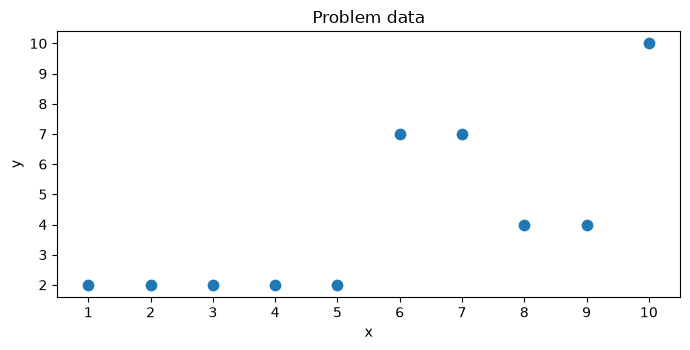

In [2]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(x, y, s=90, color="#1f77b4", zorder=3, edgecolors="white")
ax.set_xlim(0.5, 10.5)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_xticks(range(1, 11))
ax.set_title("Problem data")
plt.tight_layout()
plt.show()

## AdaBoost.R2 recap

Each round $t$:

1. Get the stump's predictions $f_t(x_i)$.
2. Absolute errors $|y_i - f_t(x_i)|$; let $D_t$ be the **largest** error.
3. Relative errors $e_i = |y_i - f_t(x_i)| / D_t$ (between 0 and 1).
4. Weighted error $\epsilon_t = \sum_i w_i e_i$.
5. $\beta_t = \epsilon_t / (1 - \epsilon_t)$, voting power $\alpha_t = \ln((1-\epsilon_t)/\epsilon_t)$.
6. Reweight: $w_i \leftarrow w_i \cdot \beta_t^{1 - e_i}$, then normalize to sum 1.

Points with large errors keep their weight ($\beta^{1-e_i} \approx 1$);
well-predicted points shrink ($\beta^{1-e_i} \approx \beta < 1$).

In [3]:
def adaboost_round(w, stump, t):
    """Run one AdaBoost.R2 round. Returns (alpha, w_new) and prints the work."""
    thr, ml, mr = stump
    f = np.where(x <= thr, ml, mr)
    err = np.abs(y - f)
    D = err.max()
    e = err / D
    eps = float((w * e).sum())
    beta = eps / (1 - eps)
    alpha = float(np.log((1 - eps) / eps))
    w_unnorm = w * beta ** (1 - e)
    w_new = w_unnorm / w_unnorm.sum()

    tbl = pd.DataFrame({
        "x": x, "y": y,
        f"Stump {t} predicts": np.round(f, 4),
        "|error|": np.round(err, 4),
        "e_i": np.round(e, 4),
        f"Weight {t}": np.round(w, 4),
    })
    print(tbl.to_string(index=False))
    print(f"\nD_{t} = {D:.4f}")
    print(f"epsilon_{t} = {eps:.4f}")
    print(f"beta_{t} = {beta:.4f}")
    print(f"alpha_{t} (voting power) = {alpha:.4f}")
    print(f"\nUnnormalized new weights (total {w_unnorm.sum():.4f}):")
    print(np.round(w_unnorm, 4))
    print(f"Weight {t+1} (normalized):")
    print(np.round(w_new, 4))
    return alpha, w_new


def plot_stump(thr, ml, mr, weights, alpha, t):
    """Scatter of the data (point size = sample weight) + stump step function."""
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.scatter(x, y, s=weights * 900, color="#1f77b4",
               zorder=3, edgecolors="white", alpha=0.85)
    ax.hlines(ml, 0.5, thr, colors="#d62728", lw=2.5)
    ax.hlines(mr, thr, 10.5, colors="#d62728", lw=2.5)
    ax.axvline(thr, color="gray", ls="--", lw=1)
    ax.set_xlim(0.5, 10.5)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_xticks(range(1, 11))
    ax.set_title(f"Stump {t}: split at x = {thr} "
                 f"(voting power $\\alpha_{t} = {alpha:.4f}$), point size = weight")
    plt.tight_layout()
    plt.show()

## Round 1 — Stump 1

In [4]:
alpha1, w = adaboost_round(w, stumps[0], t=1)
w2 = w.copy()

 x    y  Stump 1 predicts  |error|    e_i  Weight 1
 1  2.0               2.0      0.0 0.0000       0.1
 2  2.0               2.0      0.0 0.0000       0.1
 3  2.0               2.0      0.0 0.0000       0.1
 4  2.0               2.0      0.0 0.0000       0.1
 5  2.0               2.0      0.0 0.0000       0.1
 6  7.0               6.4      0.6 0.1667       0.1
 7  7.0               6.4      0.6 0.1667       0.1
 8  4.0               6.4      2.4 0.6667       0.1
 9  4.0               6.4      2.4 0.6667       0.1
10 10.0               6.4      3.6 1.0000       0.1

D_1 = 3.6000
epsilon_1 = 0.2667
beta_1 = 0.3636
alpha_1 (voting power) = 1.0116

Unnormalized new weights (total 0.5107):
[0.0364 0.0364 0.0364 0.0364 0.0364 0.043  0.043  0.0714 0.0714 0.1   ]
Weight 2 (normalized):
[0.0712 0.0712 0.0712 0.0712 0.0712 0.0843 0.0843 0.1398 0.1398 0.1958]


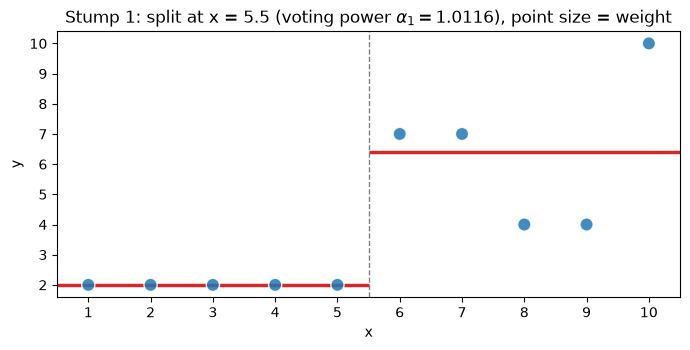

In [5]:
plot_stump(*stumps[0], weights=np.full(10, 0.1), alpha=alpha1, t=1)

## Round 2 — Stump 2

Stump 2 splits at $x \le 9.5$ to isolate the heaviest point (row 9, weight $0.1958$)
and predicts it perfectly — at the cost of the easy left points.

In [6]:
alpha2, w = adaboost_round(w, stumps[1], t=2)
w3 = w.copy()

 x    y  Stump 2 predicts  |error|    e_i  Weight 2
 1  2.0            3.7434   1.7434 0.5353    0.0712
 2  2.0            3.7434   1.7434 0.5353    0.0712
 3  2.0            3.7434   1.7434 0.5353    0.0712
 4  2.0            3.7434   1.7434 0.5353    0.0712
 5  2.0            3.7434   1.7434 0.5353    0.0712
 6  7.0            3.7434   3.2566 1.0000    0.0843
 7  7.0            3.7434   3.2566 1.0000    0.0843
 8  4.0            3.7434   0.2566 0.0788    0.1398
 9  4.0            3.7434   0.2566 0.0788    0.1398
10 10.0           10.0000   0.0000 0.0000    0.1958

D_2 = 3.2566
epsilon_2 = 0.3812
beta_2 = 0.6161
alpha_2 (voting power) = 0.4844

Unnormalized new weights (total 0.7524):
[0.0569 0.0569 0.0569 0.0569 0.0569 0.0843 0.0843 0.0895 0.0895 0.1206]
Weight 3 (normalized):
[0.0756 0.0756 0.0756 0.0756 0.0756 0.112  0.112  0.1189 0.1189 0.1603]


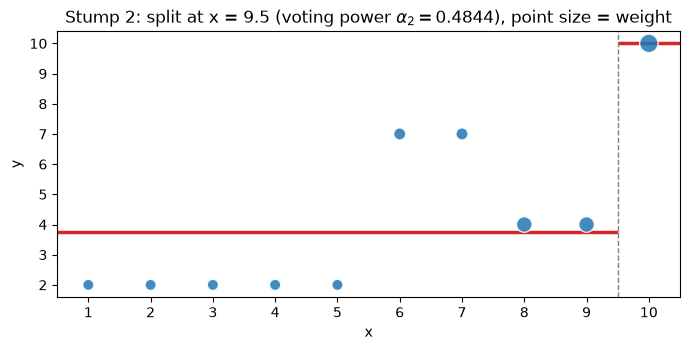

In [7]:
plot_stump(*stumps[1], weights=w2, alpha=alpha2, t=2)

## Round 3 — Stump 3

Same split as Stump 1, but the right leaf moved from $6.4$ to $6.6265$:
with the new weights it bends toward the upweighted hard points.

In [8]:
alpha3, w = adaboost_round(w, stumps[2], t=3)

 x    y  Stump 3 predicts  |error|    e_i  Weight 3
 1  2.0            2.0000   0.0000 0.0000    0.0756
 2  2.0            2.0000   0.0000 0.0000    0.0756
 3  2.0            2.0000   0.0000 0.0000    0.0756
 4  2.0            2.0000   0.0000 0.0000    0.0756
 5  2.0            2.0000   0.0000 0.0000    0.0756
 6  7.0            6.6265   0.3735 0.1107    0.1120
 7  7.0            6.6265   0.3735 0.1107    0.1120
 8  4.0            6.6265   2.6265 0.7786    0.1189
 9  4.0            6.6265   2.6265 0.7786    0.1189
10 10.0            6.6265   3.3735 1.0000    0.1603

D_3 = 3.3735
epsilon_3 = 0.3703
beta_3 = 0.5880
alpha_3 (voting power) = 0.5310

Unnormalized new weights (total 0.7336):
[0.0444 0.0444 0.0444 0.0444 0.0444 0.0699 0.0699 0.1057 0.1057 0.1603]
Weight 4 (normalized):
[0.0606 0.0606 0.0606 0.0606 0.0606 0.0952 0.0952 0.1441 0.1441 0.2186]


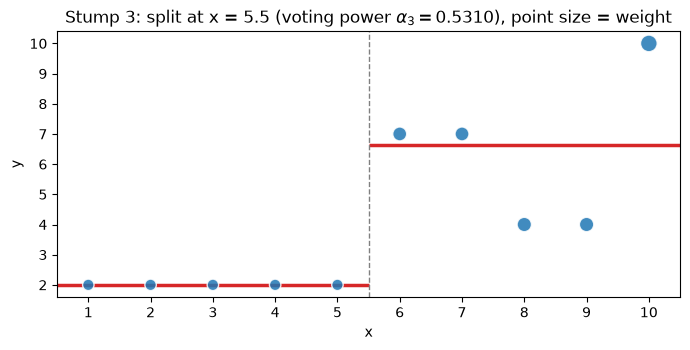

In [9]:
plot_stump(*stumps[2], weights=w3, alpha=alpha3, t=3)

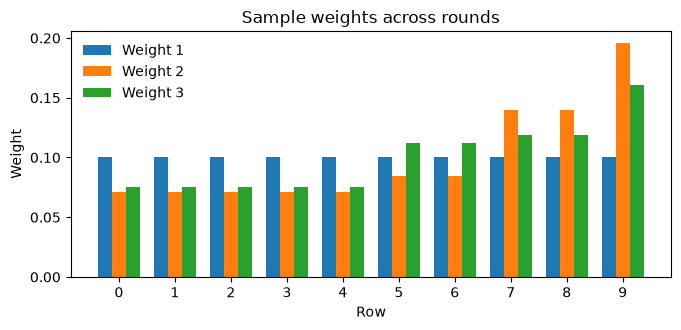

In [10]:
# Sample weights across the three rounds
fig, ax = plt.subplots(figsize=(7, 3.4))
bw = 0.25
rs = np.arange(10)
ax.bar(rs - bw, np.full(10, 0.1), bw, label="Weight 1", color="#1f77b4")
ax.bar(rs,      w2, bw, label="Weight 2", color="#ff7f0e")
ax.bar(rs + bw, w3, bw, label="Weight 3", color="#2ca02c")
ax.set_xticks(rs); ax.set_xlabel("Row"); ax.set_ylabel("Weight")
ax.set_title("Sample weights across rounds")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Combining the stumps — the weighted median

We stop after three stumps. The final AdaBoost.R2 prediction is the
**weighted median** of the stump predictions, weighted by their voting powers
$\alpha_1, \alpha_2, \alpha_3$.

### How the weighted median is computed from the stumps' predictions

For any input $x$:

1. **Collect** each stump's prediction: $f_1(x), f_2(x), f_3(x)$, each carrying
   its stump's voting power $\alpha_1, \alpha_2, \alpha_3$.
2. **Sort** the three predictions from smallest to largest (keeping each
   prediction glued to its vote).
3. **Accumulate** the votes walking through the sorted list. The first prediction
   where the accumulated vote reaches **half of the total vote**
   $(\alpha_1 + \alpha_2 + \alpha_3)/2$ is the final answer.

Why a median and not an average? The median is robust: one stump with an
extreme prediction cannot drag the answer away the way it would in a weighted
average. The vote threshold guarantees at least half the total voting power
agrees the answer should be *at least* that large, and at least half agrees it
should be *at most* that large.

Here $\alpha_1 = 1.0116$, $\alpha_2 = 0.4844$, $\alpha_3 = 0.5310$,
total vote $= 2.0270$, half $= 1.0135$.

### Worked example: $x = 4$ (so $x \le 5.5$)

| Stump | Predicts | Vote $\alpha$ |
|-------|----------|---------------|
| 3 | 2.0 | 0.5310 |
| 1 | 2.0 | 1.0116 |
| 2 | 3.7434 | 0.4844 |

Sorted by prediction, accumulate: $0.5310 \to 0.5310 + 1.0116 = 1.5426 \ge 1.0135$.
The weighted median is **2.0**. Note how close this is: Stump 1 alone holds
$1.0116$ votes, a hair short of the $1.0135$ needed — Stump 3's vote is what
pushes the median over. Every vote counts!

### The other regions

- **$5.5 < x \le 9.5$** (e.g. $x = 7$): predictions $6.4$ (1.0116), $3.7434$ (0.4844),
  $6.6265$ (0.5310). Sorted: $3.7434 \to 6.4 \to 6.6265$;
  cumulative $0.4844 \to 1.4960 \ge 1.0135$ → **6.4**.
- **$x > 9.5$** (e.g. $x = 10$): predictions $6.4$ (1.0116), $10.0$ (0.4844),
  $6.6265$ (0.5310). Sorted: $6.4 \to 6.6265 \to 10.0$;
  cumulative $1.0116 \to 1.5426 \ge 1.0135$ → **6.6265**.

Final model: $F(x) = 2.0$ for $x \le 5.5$, $6.4$ for $5.5 < x \le 9.5$,
$6.6265$ for $x > 9.5$. The code below verifies this on a fine grid and plots it.

x =  1 -> F(x) = 2.0
x =  4 -> F(x) = 2.0
x =  7 -> F(x) = 6.4
x =  8 -> F(x) = 6.4
x = 10 -> F(x) = 6.6265


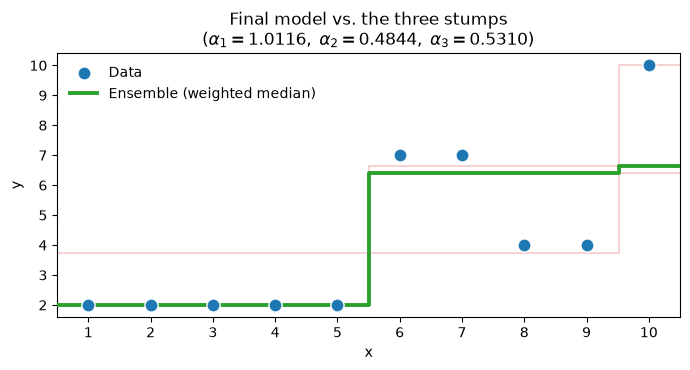

In [11]:
alphas = [alpha1, alpha2, alpha3]

def weighted_median(xv):
    """Weighted median of the three stump predictions at xv."""
    preds = sorted(
        [(a, ml if xv <= thr else mr) for (thr, ml, mr), a in zip(stumps, alphas)],
        key=lambda ap: ap[1],
    )
    total = sum(a for a, _ in preds)
    cum = 0.0
    for a, p in preds:
        cum += a
        if cum >= total / 2:
            return p

# sanity check on the training points
for xv in [1, 4, 7, 8, 10]:
    print(f"x = {xv:>2} -> F(x) = {weighted_median(xv)}")

# final model plot
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(x, y, s=90, color="#1f77b4", zorder=4, edgecolors="white", label="Data")
xs = np.linspace(0.5, 10.5, 400)
for (thr, ml, mr), a in zip(stumps, alphas):
    ax.step(xs, [ml if v <= thr else mr for v in xs], where="post",
            color="#d62728", lw=1.2, alpha=0.25, zorder=2)
ens = [weighted_median(v) for v in xs]
ax.step(xs, ens, where="post", color="#2ca02c", lw=2.8, zorder=3,
        label="Ensemble (weighted median)")
ax.set_xlim(0.5, 10.5)
ax.set_xlabel("x"); ax.set_ylabel("y")
ax.set_xticks(range(1, 11))
ax.set_title("Final model vs. the three stumps\n"
             f"($\\alpha_1={alphas[0]:.4f},\\; \\alpha_2={alphas[1]:.4f},"
             f"\\; \\alpha_3={alphas[2]:.4f}$)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

## Summary

| Stump | Split | Leaves | $\epsilon$ | Vote $\alpha$ |
|-------|-------|--------|--------------|----------------|
| 1 | $x \le 5.5$ | 2.0 / 6.4 | 0.2667 | 1.0116 |
| 2 | $x \le 9.5$ | 3.7434 / 10.0 | 0.3812 | 0.4844 |
| 3 | $x \le 5.5$ | 2.0 / 6.6265 | 0.3703 | 0.5310 |

Final model (weighted median): $F(x) = 2.0$ for $x \le 5.5$,
$6.4$ for $5.5 < x \le 9.5$, $6.6265$ for $x > 9.5$.